# Lecture 15 - More Functions and Recursion (https://bit.ly/intro_python_15)

Today is more functions :)

* Recursion: functions that call themselves
  * Base cases and recursive cases
  * Worked examples, to get comfortable with the order of execution
  * Where recursion is the natural tool (nested data, fractals), and where it is slow
* Lambda functions
* Functions as values: passing functions as arguments

# Warm-up: predict the output

Here is a function that calls itself "recursively" - building on what we learned when we introduced the stack. Before running the cell, write down what you think it prints.

In [ ]:
def countdown(n):
  if n == 0:
    print("Liftoff!")
  else:
    print(n)
    countdown(n - 1)  # the function calls itself, with a smaller number

countdown(10)

Now a small change: the `print(n)` moves to *after* the recursive call. What does this version print?

In [ ]:
def mystery(n):
  if n == 0:
    print("Liftoff!")
  else:
    mystery(n - 1)
    print(n)

mystery(10)

The numbers come out in the opposite order. `mystery(3)` can't reach its `print(3)` until `mystery(2)` has completely finished, which in turn has to wait for `mystery(1)`, and so on. Each call waits for the call it made. Keeping that picture in mind is most of what there is to understanding recursion.

# Recursion: functions can call themselves

* Functions can call each other. You know this.

* Functions can also call themselves. This is called recursion:

<img src="https://raw.githubusercontent.com/benedictpaten/intro_python/main/lecture_notebooks/figures/graffles/recursive.jpg" width=600 height=300 />

* Recursion is a powerful method for breaking down a problem into smaller, more easily solved subproblems of the same kind.

* Recursion can be direct (where a function calls itself) or indirect (e.g. where a function calls another function which then calls the first function, etc.)

* Let's look at a classic example: calculating factorials

In [3]:
# Okay, to recap, here's a non-recursive function to calculate factorials:

def factorial(x):
  """ Calculates factorials, x * x-1 * x-2 ... 1, for an integer >= 0
  """
  assert x >= 0
  j = 1
  for i in range(1, x+1):
    j *= i
  return j

for i in range(11):
  print("Factorial", i, "is", factorial(i))

Factorial 0 is 1
Factorial 1 is 1
Factorial 2 is 2
Factorial 3 is 6
Factorial 4 is 24
Factorial 5 is 120
Factorial 6 is 720
Factorial 7 is 5040
Factorial 8 is 40320
Factorial 9 is 362880
Factorial 10 is 3628800


To recap:

* factorial(x) = x * x-1 * x-2 ... 1, for an integer >= 0

We note that for x > 1:

* factorial(x) = x * factorial(x-1)

This suggests a recursive way to break the problem up:

In [4]:
def factorial_recursive(x):
  """ Calculates factorials, x * x-1 * x-2 ... 1, for an integer >= 0
  """
  assert x >= 0
  if x <= 1:
    return 1                             # Base case: small enough to answer directly
  return x * factorial_recursive(x - 1)  # Recursive case: a smaller version of the same problem

for i in range(11):
  print("Factorial", i, "is", factorial_recursive(i))

Factorial 0 is 1
Factorial 1 is 1
Factorial 2 is 2
Factorial 3 is 6
Factorial 4 is 24
Factorial 5 is 120
Factorial 6 is 720
Factorial 7 is 5040
Factorial 8 is 40320
Factorial 9 is 362880
Factorial 10 is 3628800


# The two ingredients of every recursive function

1. **A base case:** an input so simple that the answer is known without any further calls. Here, `x <= 1`.
2. **A recursive case:** the function calls itself on a *smaller* input, and uses the result to build its own answer. Here, `x * factorial_recursive(x - 1)`.

Each recursive call must move closer to the base case, otherwise the function never stops.

Short functions like this are often written on one line with a conditional expression. This is the same function:

```python
def factorial_recursive(x):
  return x * factorial_recursive(x - 1) if x > 1 else 1
```

Here's a visual that shows you what is going on, where I've replaced the variable name with its value:

<img src="https://raw.githubusercontent.com/benedictpaten/intro_python/main/lecture_notebooks/figures/graffles/factorial%20function.jpg" width=1000 height=600 />

The following figure shows the call stack (note, I've abbreviated factorial_recursive to fr):

<img src="https://raw.githubusercontent.com/benedictpaten/intro_python/main/lecture_notebooks/figures/graffles/factorial%20recursion%20stack.jpg" width=1000 height=500 />

## Watching the call stack

A useful trick when a recursive function confuses you: add an extra `depth` argument and indent your print statements by it. Calls go down the page, and answers come back up.

In [5]:
def factorial_traced(x, depth=0):
  """ factorial_recursive, with print statements that show the call stack """
  indent = "    " * depth
  print(f"{indent}factorial({x}) called")
  if x <= 1:
    result = 1
  else:
    result = x * factorial_traced(x - 1, depth + 1)
  print(f"{indent}factorial({x}) returns {result}")
  return result

factorial_traced(4)

factorial(4) called
    factorial(3) called
        factorial(2) called
            factorial(1) called
            factorial(1) returns 1
        factorial(2) returns 2
    factorial(3) returns 6
factorial(4) returns 24


24

## What happens if you forget the base case?

Predict what this will do:

In [6]:
def forever(x):
  return x * forever(x - 1)  # no base case!

forever(3)

RecursionError: maximum recursion depth exceeded

With no base case the function keeps calling itself: `forever(3)`, `forever(2)`, `forever(1)`, `forever(0)`, `forever(-1)`, ...

Every call that is waiting takes up some memory, so Python sets a limit on how deeply calls can be nested and raises a `RecursionError` when you exceed it. If you see this error, the first thing to check is your base case.

In [7]:
import sys

sys.getrecursionlimit()  # the maximum depth of nested calls Python allows

1000

# Challenge 1

In [ ]:
# Write a recursive function called "recursive_sum" to calculate the sum of whole numbers
# between two integers, x (inclusive) and y (exclusive)



# These asserts should pass
assert recursive_sum(5, 8) == 5 + 6 + 7
assert recursive_sum(3, 100) == 4947

# Revisiting earlier examples as non-recursive and recursive functions

The best way to get the hang of recursion is to write out examples. For each one, look for the base case and the recursive case.

**Counting digits**

In [9]:
def num_digits(n):
  """Returns the number of digits in the number (base 10).
  e.g. For n = 6706 returns 4
  """
  count = 0
  while n != 0:
    count = count + 1
    n = n // 10  # This is the integer division operator, it loses the remainder
  return count

num_digits(4324789)

7

We note that for n > 0:

* num_digits(n) = 1 + num_digits(n//10)

This suggests a recursive definition:

In [10]:
# Here's a recursive version

def num_digits_recursive(n):
  """Returns the number of digits in the number (base 10).
  e.g. For n = 6706 returns 4
  """
  print("n is now", n)  # Helpful print statement to see the chain of function calls
  if n == 0:
    return 0                               # Base case
  return 1 + num_digits_recursive(n // 10)  # Recursive case

num_digits_recursive(4324789)

n is now 4324789
n is now 432478
n is now 43247
n is now 4324
n is now 432
n is now 43
n is now 4
n is now 0


7

**Collatz 3n + 1 sequence**

Let's look at the Collatz 3n + 1 sequence:

* Start from some given n. The next term in the sequence is half of n if n is even, or else 3*n + 1.
* The sequence continues, only terminating when n reaches 1.

(An aside: nobody has ever found a starting number for which the sequence fails to reach 1, but nobody has been able to prove that it always does. This is the Collatz conjecture, a famous unsolved problem in mathematics.)

In [11]:
def seq3np1(n):
  """ Returns the 3n+1 sequence from n, terminating when it reaches 1.
  """
  l = []  # l is an empty list, initially
  while n != 1:
    l.append(n)  # add n to the end of the list l
    if n % 2 == 0:  # n is even
      n = n // 2
    else:  # n is odd
      n = n * 3 + 1
  l.append(n)
  return l

# Let's play with this function

seq3np1(7)

[7, 22, 11, 34, 17, 52, 26, 13, 40, 20, 10, 5, 16, 8, 4, 2, 1]

The Collatz sequence is defined recursively ("the rest of the sequence is the sequence starting from the next term"), so it maps very naturally to a recursive function:

In [12]:
# Recursive version

def seq3np1_recursive(n):
  """ Returns the 3n+1 sequence from n, terminating when it reaches 1.
  """
  if n == 1:
    return [1]  # Base case
  next_term = n // 2 if n % 2 == 0 else n * 3 + 1  # The next term in the sequence
  return [n] + seq3np1_recursive(next_term)        # Recursive case

# Let's play with this function

seq3np1_recursive(7)

[7, 22, 11, 34, 17, 52, 26, 13, 40, 20, 10, 5, 16, 8, 4, 2, 1]

**Sorting**

* It turns out there is a very simple way to write a sort recursively: the sorted list is the smallest item, followed by a sorting of everything else.

* Note, there are many sorting algorithms, and several of the fastest ones are recursive.

In [13]:
def sort_the_list(l):
  """ Function takes a list l and returns a sorted version of l"""

  # Base case: an empty list is already sorted
  if len(l) == 0:
    return []

  # Find the minimum member of l
  smallest = min(l)

  print("The min is: ", smallest, " list is now: ", l)

  # Make a copy of l without the smallest member (copying so that we don't
  # change the list that we were given)
  rest = l.copy()
  rest.remove(smallest)

  return [smallest] + sort_the_list(rest)  # This is where the recursive call
  # happens, in which a new list is created by adding together a list
  # containing the minimum value and a sorting of the remainder of the list
  # Note + here adds the lists together, i.e. [ 1 ] + [ 2, 3 ] == [ 1, 2, 3 ]

sort_the_list([4, -8, 12, 1])

The min is:  -8  list is now:  [4, -8, 12, 1]
The min is:  1  list is now:  [4, 12, 1]
The min is:  4  list is now:  [4, 12]
The min is:  12  list is now:  [12]


[-8, 1, 4, 12]

# Where recursion is really useful: things inside things

Every example so far could be written just as easily with a loop. Recursion becomes the natural tool when the *data* is recursive, that is, when it contains smaller versions of itself: folders inside folders, lists inside lists, or branches on a tree.

Here is an evolutionary tree written as nested tuples. Each tuple is a branch point, and each string is a species:

In [7]:
tree = ((("human", "chimp"), "gorilla"), ("mouse", "rat"))

# Read it as:  human and chimp are closest relatives; gorilla joins them next;
#              mouse and rat form a separate pair.

How many species are in the tree? A loop struggles here, because we don't know how deeply the tuples are nested. Recursively it is short:

* Base case: a string is a single species, so the answer is 1.
* Recursive case: a tuple is a branch point, so add up the counts of its children.

In [15]:
def count_species(tree):
  """ Counts the species (strings) in a tree made of nested tuples """
  if isinstance(tree, str):
    return 1  # Base case: a single species
  total = 0
  for child in tree:  # Recursive case: a branch point
    total += count_species(child)
  return total

print(count_species(tree))
print(count_species("yeast"))
print(count_species(((("a", "b"), ("c", ("d", "e"))), "f")))

5
1
6


The same pattern gives us the depth of the tree, i.e. the largest number of branch points between the root and any species:

In [16]:
def tree_depth(tree):
  """ The number of branch points on the longest path from the root to a species """
  if isinstance(tree, str):
    return 0
  deepest = 0
  for child in tree:
    deepest = max(deepest, tree_depth(child))
  return 1 + deepest

tree_depth(tree)

3

# Challenge 2: List the species in a tree

In [8]:
# Write a recursive function called "list_species" that takes a tree made of nested tuples
# (like the one above) and returns a list of all the species in it, in left-to-right order.
#
# Hint: follow the same pattern as count_species. What should the base case return for a
# single species? How do you combine the lists returned by the children?


# These asserts should pass
assert list_species(tree) == ["human", "chimp", "gorilla", "mouse", "rat"]
assert list_species("yeast") == ["yeast"]
assert list_species(((("a", "b"), ("c", ("d", "e"))), "f")) == ["a", "b", "c", "d", "e", "f"]

## Recursion makes pictures: a fractal tree

A fractal is a shape made of smaller copies of itself, which makes it recursion you can see.

To draw a tree: draw a branch, then draw two smaller trees at its tip, one leaning left and one leaning right. The base case is a tree with no levels left.

(This uses the plotting library matplotlib, which we'll meet properly in a later lecture. Don't worry about the plotting details; focus on the shape of the recursion.)

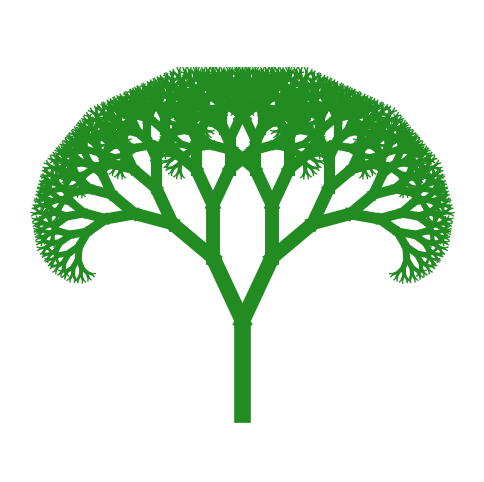

In [5]:
import math
import matplotlib.pyplot as plt

def draw_tree(x, y, angle, length, depth):
  """ Draws a branch starting at (x, y), then two smaller trees at its tip """
  if depth == 0:
    return  # Base case: nothing left to draw

  # Work out where this branch ends
  x2 = x + length * math.cos(math.radians(angle))
  y2 = y + length * math.sin(math.radians(angle))
  
  # Draw two lines to represent the branching, at the root these overlap as angle is the same
  plt.plot([x, x2], [y, y2], color="forestgreen", linewidth=depth)

  # Recursive case: two smaller trees, one leaning left and one leaning right
  draw_tree(x2, y2, angle + 25, length * 0.75, depth - 1)
  draw_tree(x2, y2, angle - 25, length * 0.75, depth - 1)

plt.figure(figsize=(6, 6))
draw_tree(0, 0, 90, 10, 12)
plt.axis("equal")
plt.axis("off")
plt.show()

Things to try: change the two angles (try 25 and 40 for a tree in the wind), the shrink factor 0.75, or the depth. How many branches are drawn at depth 9? At depth 10? Can you see a simple analytic expression?

# A warning: recursion can be very slow if it repeats work

The Fibonacci numbers are 0, 1, 1, 2, 3, 5, 8, 13, ... where each number is the sum of the previous two. The definition is recursive, so the code writes itself:

In [18]:
def fib(n):
  """ Returns the nth Fibonacci number """
  if n < 2:
    return n                       # Base cases: fib(0) = 0 and fib(1) = 1
  return fib(n - 1) + fib(n - 2)   # Recursive case: note there are TWO recursive calls

[fib(i) for i in range(15)]

[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]

In [19]:
import time

start = time.time()
print(fib(32))
print(f"That took {time.time() - start:.2f} seconds")

2178309
That took 0.25 seconds


Working out the 32nd Fibonacci number by hand takes 31 additions, so why does the computer need so long? Let's count how many times `fib` gets called with each value:

In [20]:
call_counts = {}  # maps n to the number of times fib_counted(n) was called

def fib_counted(n):
  call_counts[n] = call_counts.get(n, 0) + 1  # the second argument to get is the value if the dictionary
  # is empty for that key - neat trick to know
  if n < 2:
    return n
  return fib_counted(n - 1) + fib_counted(n - 2)

fib_counted(32)

print("Total calls:", sum(call_counts.values()))
for n in [31, 20, 10, 2, 1]:
  print(f"fib({n}) was worked out {call_counts[n]} times")

Total calls: 7049155
fib(31) was worked out 1 times
fib(20) was worked out 233 times
fib(10) was worked out 28657 times
fib(2) was worked out 1346269 times
fib(1) was worked out 2178309 times


`fib(32)` calls `fib(31)` and `fib(30)`. But `fib(31)` also calls `fib(30)`, and both of those call `fib(29)`, and so on. The same answers are recomputed over and over, and the number of calls roughly doubles each time n goes up by one.

The fix is to remember answers we have already worked out. This is called *memoization*:

In [21]:
memo = {}  # maps n to fib(n), for every n we've already worked out

def fib_memo(n):
  """ Returns the nth Fibonacci number, remembering previous answers """
  if n < 2:
    return n
  if n not in memo:
    memo[n] = fib_memo(n - 1) + fib_memo(n - 2) # this guarantees we'll only 
    # compute fib_memo(n) once for a given n
  return memo[n]

start = time.time()
print(fib_memo(32))
print(fib_memo(200))
print(f"That took {time.time() - start:.5f} seconds")

2178309
280571172992510140037611932413038677189525
That took 0.00018 seconds


Python can do the remembering for you using the `@lru_cache` decorator from `functools`, but that is a more advanced topic!

# Recursion summary

* Recursion is a powerful technique that can be used to write elegant solutions to problems.

* A recursive function needs a base case, and a recursive case that moves towards the base case.

* Recursive solutions solve a problem by solving smaller subproblems of the same type. Recursion is at its best when the data is nested (trees, folders, lists within lists) or the problem branches.

* For simple repetition a loop is usually the better choice in Python: it is faster, and it can't run into the recursion limit.

* If a recursive function recomputes the same subproblems, memoize it.

* Recursion challenges your understanding of the order of execution, but it is consistent with everything we've learned.

* I've set some challenges, but here are even more: https://www.geeksforgeeks.org/recursion-practice-problems-solutions/

# Challenge 3: Enumerate all boolean strings of length n

In [ ]:
# A boolean string of length n is a string of n 0 or 1 characters.

# The challenge is write a recursive function to enumerate the set of boolean strings of a given length,
# e.g. for n = 3 we have '000' '001' '010' '011' '100' '101' '110' '111'

# The problem is naturally recursive because the set of boolean strings, T, of length n+1
# can be formed from the set S of boolean strings of length n by taking each string in S
# and appending a 0 and, separately, a 1 to form a set 2x as large as S.
# i.e.
# for s in S
#   T.append(s + '0')
#   T.append(s + '1')

def boolean_strings(n):
  """ Returns the set of boolean strings of length n
  """
  # Code to complete

boolean_strings(3)

# Challenge 4: Enumerate all permutations of a set

In [ ]:
# Given a set S of elements, say integers { 0, 1, 2 },
# a permutation is an ordering of the elements, e.g:
# (0, 1, 2) or (1, 0, 2) or (2, 1, 0), etc.

# The challenge is to write a recursive function to enumerate all possible permutations of an input set.

# The problem is naturally recursive because the set of permutations R of a set S containing a member x
# can be constructed from the set of permutations, T, of S - { x } (S after removing x) as follows:

# For each P = y_1, y_2, ..., y_n permutation in T, create n+1 permutations containing x:
#   x, y_1, y_2, ..., y_n
#   y_1, x, y_2, ..., y_n
#   y_1, y_2, x, ..., y_n
#   ...
#   y_1, y_2, ..., x, y_n
#   y_1, y_2, ..., y_n, x

# For example for S = { 0, 1, 2 } and x=2
# then S - { 2 } = { 0, 1 } and
# T = { (0,1), (1,0) }
# then R = { (2,0,1), (0,2,1), (0,1,2), (2,1,0), (1,2,0), (1,0,2) }

def permutations(S):
  """ Returns the permutations of a set
  """
  # Code to complete

permutations((0,1,2))

# Lambdas

What if you want to define a little function?

Lambdas are one-liner functions:

In [25]:
fn = lambda x, y : x + y > 10

# The lambda definition is equivalent to
#def fn(x, y):
#  return x + y > 10

fn(5, 10)

True

Reading a lambda: the names before the colon are the arguments, and the single expression after the colon is what gets returned. There is no `return` keyword and no name.

Lambda functions are handy when you want to define something small, e.g:

In [26]:
# A little piece of math

import math

phred_score = lambda p : -10 * math.log10(p)  # Calculates the phred score of a probability

print(phred_score(0.01))
print(phred_score(0.001))

# Phred scores are how DNA sequencing machines report their confidence in each base:
# a score of 20 means a 1 in 100 chance that the base is wrong, 30 means 1 in 1000.

# It's much cleaner to define a function than to
# repeat the above -10 * math.log10(p) all over your code

20.0
30.0


In [27]:
# A small iteration on a list

sum_even = lambda x : sum([ i for i in x if i % 2 == 0 ])  # Sum the even numbers in a list

sum_even([2, 4, 6, 1, 9])

# This is cleaner than copying the above list comprehension every place

12

* A lambda is just a compact way to write a function. Anything you can do with a lambda you can also do with `def`.

* A lambda can only contain a single expression: no loops, no assignments, no `if` statements (though a conditional expression `a if test else b` is allowed).

* If you find yourself giving a lambda a name, as we did above, a `def` is usually the clearer choice. Lambdas are most useful when we want to write a small function right at the place we use it, without naming it, as we'll see next.

* If you're interested: https://en.wikipedia.org/wiki/Anonymous_function (functions without names). The lambda name comes from Alonzo Church, who created the lambda calculus.

# Functions are values too

In Python a function is an object, like a number or a string. That means you can give it another name, put it in a list or dictionary, and hand it to another function.

The key is the difference between `shout`, which is the function itself, and `shout("hi")`, which calls it:

In [28]:
def shout(text):
  return text.upper() + "!"

yell = shout          # No parentheses: we're not calling shout, just giving it a second name

print(yell("hello"))
print(shout)          # The function itself is an object we can print

HELLO!
<function shout at 0x7f7e1c339080>


Here is a small calculator that stores functions in a dictionary:

In [29]:
operations = {
  "+": lambda a, b: a + b,
  "-": lambda a, b: a - b,
  "*": lambda a, b: a * b,
  "/": lambda a, b: a / b,
}

for symbol in operations:
  fn = operations[symbol]  # Look up the function...
  print(7, symbol, 2, "=", fn(7, 2))  # ...and call it

7 + 2 = 9
7 - 2 = 5
7 * 2 = 14
7 / 2 = 3.5


# Functions can be passed around as arguments

Passing functions as arguments to another function is a powerful trick.

In [30]:
# First consider a function for sorting a list of strings

some_strings = [ "once", "upon", "a", "time", "there", "lived", "a", "wicked", "teacher"]

sorted_strings = sorted(some_strings)  # The inbuilt sorted function
# returns a lexicographically sorted version of the input list

print(sorted_strings)

['a', 'a', 'lived', 'once', 'teacher', 'there', 'time', 'upon', 'wicked']


But what if we wanted to sort the strings by some other property? For example, if they were date strings or time stamps or some other encoding? It turns out that sorted() takes a "key" argument, which is a function that works out the value to sort each element by.

In [31]:
# Here, let's just sort them by the length of each string.

some_strings = [ "once", "upon", "a", "time", "there", "lived", "a", "wicked", "teacher"]

sorted(some_strings, key=len)  # We use the builtin "len" to sort the elements in the list
# by their lengths. Note we write len and not len(): we are handing over the function, not calling it

# This works by calling len() on each element of the list, then using the resulting values to sort
# the elements

['a', 'a', 'once', 'upon', 'time', 'there', 'lived', 'wicked', 'teacher']

We can use inline lambdas to sort by anything we like:

In [32]:
some_strings = [ "once", "upon", "a", "time", "there", "lived", "a", "wicked", "teacher"]

sorted(some_strings, key=lambda x : x[::-1])  # x[::-1] is the reverse string of x,
# so this sorts the strings according to their reversals

['a', 'a', 'wicked', 'lived', 'once', 'time', 'there', 'upon', 'teacher']

This is the usual way to sort records. Here each gene is a tuple of (name, chromosome, approximate length in bases):

In [33]:
genes = [("BRCA1", 17, 81000), ("TP53", 17, 19000), ("CFTR", 7, 189000), ("HBB", 11, 1600), ("TTN", 2, 282000)]

print(sorted(genes, key=lambda gene: gene[2]))                # sort by length
print(sorted(genes, key=lambda gene: gene[2], reverse=True))  # longest first
print(sorted(genes, key=lambda gene: (gene[1], gene[0])))     # by chromosome, then by name

[('HBB', 11, 1600), ('TP53', 17, 19000), ('BRCA1', 17, 81000), ('CFTR', 7, 189000), ('TTN', 2, 282000)]
[('TTN', 2, 282000), ('CFTR', 7, 189000), ('BRCA1', 17, 81000), ('TP53', 17, 19000), ('HBB', 11, 1600)]
[('TTN', 2, 282000), ('CFTR', 7, 189000), ('HBB', 11, 1600), ('BRCA1', 17, 81000), ('TP53', 17, 19000)]


`max()` and `min()` take a `key` in the same way:

In [34]:
print("Longest gene: ", max(genes, key=lambda gene: gene[2]))
print("Shortest gene:", min(genes, key=lambda gene: gene[2]))

Longest gene:  ('TTN', 2, 282000)
Shortest gene: ('HBB', 11, 1600)


A very common use: you have counted things in a dictionary, and want the most common first.

In [35]:
text = "the cat sat on the mat and the dog sat on the cat"

counts = {}
for word in text.split():
  counts[word] = counts.get(word, 0) + 1 # again, using get here allows us to
  # specify a value (here 0) if the word is not in the dictionary

# counts.items() gives (word, count) pairs; we sort them by the count
sorted(counts.items(), key=lambda pair: pair[1], reverse=True)

[('the', 4),
 ('cat', 2),
 ('sat', 2),
 ('on', 2),
 ('mat', 1),
 ('and', 1),
 ('dog', 1)]

## Writing your own function that takes a function

There is nothing special about `sorted`. Any function you write can accept a function as an argument and call it:

In [36]:
def apply_to_all(fn, items):
  """ Returns a new list made by calling fn on every item in items """
  result = []
  for item in items:
    result.append(fn(item))
  return result

print(apply_to_all(len, some_strings))
print(apply_to_all(lambda s: s.upper(), some_strings))
print(apply_to_all(phred_score, [0.1, 0.01, 0.001]))

[4, 4, 1, 4, 5, 5, 1, 6, 7]
['ONCE', 'UPON', 'A', 'TIME', 'THERE', 'LIVED', 'A', 'WICKED', 'TEACHER']
[10.0, 20.0, 30.0]


Python has this built in. It is called `map`, and its partner `filter` keeps only the items for which a function returns True. You will see both in other people's code, although a list comprehension often reads more clearly:

In [37]:
print(list(map(len, some_strings)))
print([len(s) for s in some_strings])  # the same thing as a list comprehension

print(list(filter(lambda s: len(s) > 4, some_strings)))
print([s for s in some_strings if len(s) > 4])  # the same thing as a list comprehension

[4, 4, 1, 4, 5, 5, 1, 6, 7]
[4, 4, 1, 4, 5, 5, 1, 6, 7]
['there', 'lived', 'wicked', 'teacher']
['there', 'lived', 'wicked', 'teacher']


* The use of functions as arguments is a powerful technique for writing very general functions.

* `sorted()` only has to know how to sort. By passing it a function, we can produce any ordering we like without changing `sorted()` itself.

# Challenge 5

In [ ]:
someStrings = [ "once", "upon", "a", "time", "there", "lived", "a", "wicked", "teacher"]

sorted(someStrings, key=xx)  # replace xx with a lambda function such that the
# strings will be sorted only by the even numbered elements in the string, e.g. for string "once" it would be sorted
# by the string "ne" (the 2nd and 4th elements).

# Homework

* Go to Canvas and complete the lecture quiz, which involves completing each challenge problem
* ZyBooks Reading 15

# Practice Problems

In [ ]:
# Problem 1: Recursive Power Function
# Write a recursive function that calculates x raised to the power n (x^n)
# Do not use the built-in power operator ** or math.pow()

def recursive_power(x, n):
  """Calculate x raised to power n using recursion.
  For example: recursive_power(2, 3) should return 8"""
  # Write your code here
  pass

# Tests for Problem 1
assert recursive_power(2, 3) == 8
assert recursive_power(5, 0) == 1
assert recursive_power(3, 4) == 81

In [ ]:
# Problem 2: List Element Product
# Write a recursive function, list_product, that returns the product of all numbers in an input list

# Write your code here

# Tests for Problem 2
assert list_product([2, 3, 4]) == 24
assert list_product([1, 2, 3, 4, 5]) == 120
assert list_product([]) == 1

In [ ]:
# Problem 3: Palindrome Checker
# Write a recursive function that checks if a string is a palindrome

def is_palindrome(s):
  """Return True if string s is a palindrome, False otherwise.
  For example: is_palindrome("racecar") should return True"""
  # Write your code here
  pass

# Tests for Problem 3
assert is_palindrome("racecar") == True
assert is_palindrome("hello") == False
assert is_palindrome("") == True
assert is_palindrome("a") == True
assert is_palindrome("ab") == False

In [ ]:
# Problem 4: Sort by Custom Key
# Write a lambda function to sort the list of strings by the last character
# Replace the "lambda_function" placeholder below with your lambda

strings = ["python", "javascript", "ruby", "java"]
sorted_strings = sorted(strings, key=lambda_function)  # Replace with your lambda function

# Tests for Problem 4
assert sorted_strings == ["java", "python", "javascript", "ruby"]

In [ ]:
# Problem 5: Custom Filter Function
# Write a function that takes a list and a function as arguments
# and returns a new list containing only elements where the function returns True

def custom_filter(lst, fn):
  """Filter lst using function fn.
  For example: custom_filter([1,2,3,4], lambda x: x % 2 == 0) should return [2,4]"""
  # Write your code here
  pass

# Tests for Problem 5
assert custom_filter([1,2,3,4], lambda x: x % 2 == 0) == [2,4]
assert custom_filter([1,2,3,4,5], lambda x: x > 3) == [4,5]
assert custom_filter([], lambda x: x > 0) == []

In [ ]:
# Problem 6: Nested Sum
# Write a recursive function that adds up all the numbers in a list that may contain
# other lists, nested to any depth.
# Hint: isinstance(item, list) is True if item is a list.

def nested_sum(items):
  """Return the sum of all the numbers in a (possibly nested) list.
  For example: nested_sum([1, [2, 3], [4, [5]]]) should return 15"""
  # Write your code here
  pass

# Tests for Problem 6
assert nested_sum([1, 2, 3]) == 6
assert nested_sum([1, [2, 3], [4, [5, [6]]]]) == 21
assert nested_sum([]) == 0
assert nested_sum([[[[7]]]]) == 7

In [ ]:
# Problem 7: Towers of Hanoi
# A classic puzzle. There are three pegs. A stack of n disks sits on the first peg, largest
# at the bottom. Move the whole stack to another peg, moving one disk at a time and never
# placing a larger disk on top of a smaller one.
#
# The recursive insight: to move n disks from the source peg to the target peg,
#   1. move the top n-1 disks from source to the spare peg (using target as the spare)
#   2. move the largest disk from source to target
#   3. move the n-1 disks from the spare peg to target (using source as the spare)
#
# Write a recursive function that returns the list of moves, each one a tuple (from_peg, to_peg).
# (Legend has it that monks are solving this puzzle with 64 disks. At one move per second
# the 2**64 - 1 moves would take them about 585 billion years.)

def hanoi(n, source, target, spare):
  """Return the list of moves needed to move n disks from source to target.
  For example: hanoi(1, "A", "C", "B") should return [("A", "C")]"""
  # Write your code here
  pass

# Tests for Problem 7
assert hanoi(1, "A", "C", "B") == [("A", "C")]
assert hanoi(2, "A", "C", "B") == [("A", "B"), ("A", "C"), ("B", "C")]
moves = hanoi(3, "A", "C", "B")
assert len(moves) == 7
assert moves[0] == ("A", "C") and moves[-1] == ("A", "C")
assert len(hanoi(10, "A", "C", "B")) == 2**10 - 1